<a href="https://colab.research.google.com/github/70494455-prog/Analisis-con-3-modelos-del-Dataset-UNSW-NB15/blob/main/Comparacion_DT_RF_MLP_UNSW_NB15_C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Detección de Intrusiones en Redes: Árbol de Decisión, Random Forest y Perceptrón Multicapa (MLP)

**Proyecto Unidad I — Modelo predictivo utilizando algoritmos de aprendizaje supervisado**

|  |  |
|---|---|
|**Discentes**|Cahuana Alfaro Edson - Cutisaca Coanqui Andersson - Vera Velasquez Alvaro|
| **Dataset** | UNSW-NB15 (archivo `UNSW-NB15_1.csv`) |
| **Problema** | Clasificación binaria: ¿la conexión de red corresponde a tráfico normal o a un ataque? |
| **Variable objetivo** | `label` (0 = tráfico normal, 1 = ataque) |
| **Modelos comparados** | Árbol de Decisión, Random Forest y MLP |
| **Fuente** | https://research.unsw.edu.au/projects/unsw-nb15-dataset |

## 1. Importación de librerías

In [ ]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import VarianceThreshold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    mean_squared_error, mean_absolute_error,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

print('Librerías cargadas correctamente ✓')

Librerías cargadas correctamente ✓


## 2. Carga y presentación del dataset

**Fuente del dataset.** UNSW-NB15 fue generado en 2015 por el Australian Centre for Cyber Security (ACCS) de la University of New South Wales (UNSW) (Moustafa & Slay, 2015). Se encuentra disponible en https://research.unsw.edu.au/projects/unsw-nb15-dataset. En este trabajo se utiliza el archivo `UNSW-NB15_1.csv`, una de las cuatro particiones en que se distribuye el conjunto completo, cuyas columnas se nombran según el archivo `NUSW-NB15_features.csv`.

**Descripción general.** Es un conjunto de datos que simula tráfico de red sintético moderno, combinando actividades cotidianas normales con nueve categorías de ciberataques: *Fuzzers, Analysis, Backdoors, DoS, Exploits, Generic, Reconnaissance, Shellcode* y *Worms*. Cada registro representa una conexión de red descrita por variables de flujo, de contenido y de tiempo, y está etiquetado con la categoría del ataque (`attack_cat`) y con una etiqueta binaria (`label`). Las variables disponibles, el tamaño del dataset (filas y columnas) y el tipo de datos se presentan en las celdas siguientes.

**Justificación.** El dataset es relevante para la ciberseguridad moderna, ya que supera las limitaciones de conjuntos de datos obsoletos como KDD99 (Moustafa & Slay, 2016). Permite entrenar algoritmos supervisados para detectar ciberamenazas con patrones de tráfico complejos y, por su estructura tabular con variables numéricas y categóricas y una etiqueta binaria, resulta adecuado para comparar modelos de clasificación.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Nombres de columnas según el archivo NUSW-NB15_features.csv
columnas = [
    'srcip','sport','dstip','dsport','proto','state','dur','sbytes','dbytes',
    'sttl','dttl','sloss','dloss','service','Sload','Dload','Spkts','Dpkts',
    'swin','dwin','stcpb','dtcpb','smeansz','dmeansz','trans_depth','res_bdy_len',
    'Sjit','Djit','Stime','Ltime','Sintpkt','Dintpkt','tcprtt','synack','ackdat',
    'is_sm_ips_ports','ct_state_ttl','ct_flw_http_mthd','is_ftp_login','ct_ftp_cmd',
    'ct_srv_src','ct_srv_dst','ct_dst_ltm','ct_src_ltm','ct_src_dport_ltm',
    'ct_dst_sport_ltm','ct_dst_src_ltm','attack_cat','label'
]

ruta_archivo = '/content/drive/MyDrive/UNSW-NB15_1.csv'
df = pd.read_csv(ruta_archivo, header=None, names=columnas, encoding='latin-1', low_memory=False)

print('Dataset cargado correctamente ✓')
print(f'Tamaño del dataset: {df.shape[0]:,} filas × {df.shape[1]} columnas')

Dataset cargado correctamente ✓
Tamaño del dataset: 700,001 filas × 49 columnas


### 2.1 Exploración inicial

In [ ]:
df.head()

,srcip,sport,dstip,dsport,proto,state,dur,sbytes,dbytes,sttl,...,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,attack_cat,label
0,ï»¿59.166.0.0,1390,149.171.126.6,53,udp,CON,0.001055,132,164,31,...,0,3,7,1,3,1,1,1,NaN,0
1,59.166.0.0,33661,149.171.126.9,1024,udp,CON,0.036133,528,304,31,...,0,2,4,2,3,1,1,2,NaN,0
2,59.166.0.6,1464,149.171.126.7,53,udp,CON,0.001119,146,178,31,...,0,12,8,1,2,2,1,1,NaN,0
3,59.166.0.5,3593,149.171.126.5,53,udp,CON,0.001209,132,164,31,...,0,6,9,1,1,1,1,1,NaN,0
4,59.166.0.3,49664,149.171.126.0,53,udp,CON,0.001169,146,178,31,...,0,7,9,1,1,1,1,1,NaN,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700001 entries, 0 to 700000
Data columns (total 49 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   srcip             700001 non-null  object 
 1   sport             700001 non-null  object 
 2   dstip             700001 non-null  object 
 3   dsport            700001 non-null  object 
 4   proto             700001 non-null  object 
 5   state             700001 non-null  object 
 6   dur               700001 non-null  float64
 7   sbytes            700001 non-null  int64  
 8   dbytes            700001 non-null  int64  
 9   sttl              700001 non-null  int64  
 10  dttl              700001 non-null  int64  
 11  sloss             700001 non-null  int64  
 12  dloss             700001 non-null  int64  
 13  service           700001 non-null  object 
 14  Sload             700001 non-null  float64
 15  Dload             700001 non-null  float64
 16  Spkts             70

In [ ]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
dur,700001.0,8.600000e-01,2.594000e+01,0.000000e+00,0.000000e+00,3.000000e-02,3.500000e-01,8.786640e+03
sbytes,700001.0,5.009640e+03,4.489868e+04,0.000000e+00,4.240000e+02,2.024000e+03,3.806000e+03,1.367739e+07
dbytes,700001.0,4.833038e+04,1.860516e+05,0.000000e+00,3.040000e+02,3.380000e+03,2.243200e+04,1.465542e+07
sttl,700001.0,3.851000e+01,4.000000e+01,0.000000e+00,3.100000e+01,3.100000e+01,3.100000e+01,2.550000e+02
dttl,700001.0,3.198000e+01,3.045000e+01,0.000000e+00,2.900000e+01,2.900000e+01,2.900000e+01,2.540000e+02
sloss,700001.0,6.330000e+00,1.886000e+01,0.000000e+00,0.000000e+00,4.000000e+00,7.000000e+00,5.096000e+03
dloss,700001.0,2.133000e+01,6.473000e+01,0.000000e+00,0.000000e+00,5.000000e+00,1.600000e+01,5.483000e+03
Sload,700001.0,6.024271e+06,5.181492e+07,0.000000e+00,7.885915e+04,5.362718e+05,1.078489e+06,5.268000e+09
Dload,700001.0,3.011023e+06,4.499952e+06,0.000000e+00,7.640437e+04,6.686759e+05,3.856223e+06,1.287619e+08
Spkts,700001.0,4.175000e+01,8.020000e+01,0.000000e+00,4.000000e+00,1.600000e+01,5.200000e+01,1.020000e+04


### 2.2 Tipos de datos

Las variables se clasifican según su naturaleza: **cualitativas nominales** (categorías sin orden, incluidos los identificadores y las variables binarias), **cuantitativas discretas** (conteos y valores enteros) y **cuantitativas continuas** (mediciones que admiten decimales). No se identifican variables cualitativas ordinales.

In [ ]:
identificadores = ['srcip', 'sport', 'dstip', 'dsport']
categoricas = ['proto', 'state', 'service', 'attack_cat']
binarias = ['is_sm_ips_ports', 'is_ftp_login', 'label']
continuas = ['dur', 'Sload', 'Dload', 'Sjit', 'Djit', 'Sintpkt', 'Dintpkt', 'tcprtt', 'synack', 'ackdat']


def clasificar_variable(nombre):
    if nombre in identificadores + categoricas + binarias:
        return 'Cualitativa', 'Nominal'
    if nombre in continuas:
        return 'Cuantitativa', 'Continua'
    return 'Cuantitativa', 'Discreta'


tabla_tipos = pd.DataFrame({
    'variable': df.columns,
    'naturaleza': [clasificar_variable(c)[0] for c in df.columns],
    'tipo': [clasificar_variable(c)[1] for c in df.columns],
    'dtype leído': df.dtypes.astype(str).values
})

print(tabla_tipos.groupby(['naturaleza', 'tipo']).size().rename('número de variables').to_string())
print()
tabla_tipos

naturaleza    tipo    
Cualitativa   Nominal     11
Cuantitativa  Continua    10
              Discreta    28



,variable,naturaleza,tipo,dtype leído
0,srcip,Cualitativa,Nominal,object
1,sport,Cualitativa,Nominal,object
2,dstip,Cualitativa,Nominal,object
3,dsport,Cualitativa,Nominal,object
4,proto,Cualitativa,Nominal,object
5,state,Cualitativa,Nominal,object
6,dur,Cuantitativa,Continua,float64
7,sbytes,Cuantitativa,Discreta,int64
8,dbytes,Cuantitativa,Discreta,int64
9,sttl,Cuantitativa,Discreta,int64


## 3. Desarrollo del proyecto

### A. Preguntas de investigación

- **PI1:** ¿Cuáles son los protocolos de red (`proto`) y servicios (`service`) más frecuentes asociados a anomalías o ataques cibernéticos?
- **PI2:** ¿Existe una diferencia significativa en la duración de la conexión (`dur`) o en los bytes transmitidos (`sbytes`/`dbytes`) entre el tráfico legítimo y los ciberataques?
- **PI3:** ¿Qué algoritmo de aprendizaje supervisado (Árbol de Decisión, Random Forest o MLP) logra mayor rendimiento en la detección temprana de intrusiones?

Para PI3, la *detección temprana* se operacionaliza mediante tres criterios: (i) el **recall de la clase ataque**, es decir, la proporción de ataques detectados (los falsos negativos son ataques no detectados); (ii) el **F1 de la clase ataque**, como medida de equilibrio entre precisión y recall; y (iii) el **tiempo de predicción**, dado que una detección temprana requiere clasificar las conexiones con rapidez.

### B. Limpieza y preparación de los datos

#### B.1 Valores nulos

In [ ]:
nulos = df.isnull().sum()
print('Columnas con valores nulos:')
print(nulos[nulos > 0])
print(f'\nTotal de valores nulos: {nulos.sum():,}')

Columnas con valores nulos:
attack_cat    677786
dtype: int64

Total de valores nulos: 677,786


La columna `attack_cat` presenta valores nulos en los registros de tráfico normal, por lo que se reemplazan por la categoría `Normal`. Asimismo, se unifica la denominación de la categoría *Backdoors*.

In [ ]:
df['attack_cat'] = df['attack_cat'].fillna('Normal').str.strip().replace({'Backdoor': 'Backdoors'})

print('Distribución por categoría de ataque:')
print(df['attack_cat'].value_counts().to_string())

Distribución por categoría de ataque:
attack_cat
Normal            677786
Generic             7522
Exploits            5409
Fuzzers             5051
Reconnaissance      1759
DoS                 1167
Backdoors            534
Analysis             526
Shellcode            223
Worms                 24


#### B.2 Registros duplicados

In [ ]:
duplicados = df.duplicated().sum()
print(f'Registros duplicados encontrados: {duplicados:,}')

df = df.drop_duplicates()
print(f'Registros restantes: {len(df):,}')

Registros duplicados encontrados: 59,213
Registros restantes: 640,788


#### B.3 Eliminación de columnas no predictoras

Se eliminan `srcip` y `dstip` (direcciones IP, que son identificadores), `Stime` y `Ltime` (marcas de tiempo de captura) y `attack_cat` (nombre del ataque, que permitiría deducir directamente la variable objetivo).

In [ ]:
cols_eliminar = ['srcip', 'dstip', 'Stime', 'Ltime', 'attack_cat']
df = df.drop(columns=cols_eliminar)
print(f'Columnas eliminadas: {cols_eliminar}')
print(f'Columnas restantes: {df.shape[1]}')

Columnas eliminadas: ['srcip', 'dstip', 'Stime', 'Ltime', 'attack_cat']
Columnas restantes: 44


#### B.4 Conversión a tipo numérico

Los puertos (`sport`, `dsport`) pueden estar expresados en formato hexadecimal, por lo que se convierten a enteros. Las columnas `ct_flw_http_mthd`, `is_ftp_login` y `ct_ftp_cmd` son conteos o indicadores que pueden contener vacíos o espacios; se convierten a numérico y los valores ausentes se imputan con 0 (ausencia de la acción registrada).

In [ ]:
def convertir_puerto(valor):
    try:
        return int(str(valor), 16) if str(valor).startswith('0x') else int(valor)
    except Exception:
        return 0


df['sport'] = df['sport'].apply(convertir_puerto)
df['dsport'] = df['dsport'].apply(convertir_puerto)

for col in ['ct_flw_http_mthd', 'is_ftp_login', 'ct_ftp_cmd']:
    df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)

print('Valores nulos restantes:', df.isnull().sum().sum())
print('Columnas no numéricas restantes:', df.select_dtypes(exclude=[np.number]).columns.tolist())

Valores nulos restantes: 0
Columnas no numéricas restantes: ['proto', 'state', 'service']


### C. Análisis exploratorio de datos (EDA)

#### C.1 Definición de la variable objetivo

La variable objetivo es `label`: **0** = tráfico normal y **1** = ataque. Se trata, por tanto, de un problema de **clasificación binaria**.

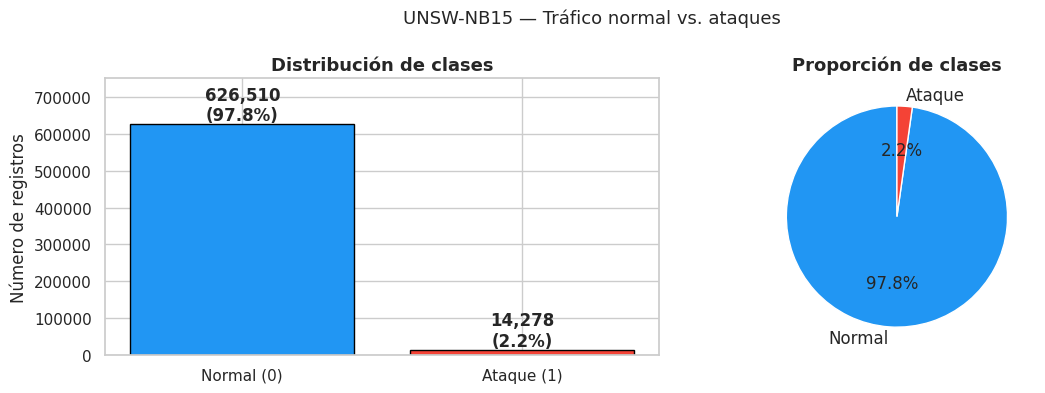

Tráfico normal: 626,510 (97.8%)
Ataques:        14,278 (2.2%)


In [ ]:
conteo = df['label'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(['Normal (0)', 'Ataque (1)'], [conteo[0], conteo[1]],
            color=['#2196F3', '#F44336'], edgecolor='black')
axes[0].set_title('Distribución de clases', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Número de registros')
for i, v in enumerate([conteo[0], conteo[1]]):
    axes[0].text(i, v, f'{v:,}\n({v/len(df)*100:.1f}%)', ha='center', va='bottom', fontweight='bold')
axes[0].set_ylim(0, max(conteo[0], conteo[1]) * 1.2)

axes[1].pie([conteo[0], conteo[1]], labels=['Normal', 'Ataque'],
            colors=['#2196F3', '#F44336'], autopct='%1.1f%%',
            startangle=90, textprops={'fontsize': 12})
axes[1].set_title('Proporción de clases', fontsize=13, fontweight='bold')

plt.suptitle('UNSW-NB15 — Tráfico normal vs. ataques', fontsize=13)
plt.tight_layout()
plt.show()

print(f'Tráfico normal: {conteo[0]:,} ({conteo[0]/len(df)*100:.1f}%)')
print(f'Ataques:        {conteo[1]:,} ({conteo[1]/len(df)*100:.1f}%)')

#### C.2 PI1: Protocolos y servicios asociados a ataques

Para cada protocolo y servicio se calcula el número de registros de ataque, la tasa de ataque (proporción de registros del grupo que son ataques) y su participación en el total de ataques. Según la documentación del dataset, el valor `-` en `service` corresponde a servicios poco frecuentes o no identificados.

In [ ]:
def resumen_por_categoria(columna):
    tabla = df.groupby(columna)['label'].agg(total='count', ataques='sum')
    tabla['tasa_ataque'] = tabla['ataques'] / tabla['total'] * 100
    tabla['participacion_en_ataques'] = tabla['ataques'] / tabla['ataques'].sum() * 100
    return tabla.sort_values('ataques', ascending=False)


tabla_proto = resumen_por_categoria('proto')
tabla_servicio = resumen_por_categoria('service').rename(index={'-': 'ninguno (-)'})

print('Top 10 protocolos por número de ataques:')
print(tabla_proto.head(10).round(2).to_string())
print('\nTop 10 servicios por número de ataques:')
print(tabla_servicio.head(10).round(2).to_string())

Top 10 protocolos por número de ataques:
        total  ataques  tasa_ataque  participacion_en_ataques
proto                                                        
tcp    457028     8622         1.89                     60.39
udp    179265     4326         2.41                     30.30
unas      535      535       100.00                      3.75
ospf     1052       77         7.32                      0.54
sctp       33       33       100.00                      0.23
any        15       15       100.00                      0.11
emcon      10       10       100.00                      0.07
nvp        10       10       100.00                      0.07
snp        10       10       100.00                      0.07
vmtp       10       10       100.00                      0.07

Top 10 servicios por número de ataques:
              total  ataques  tasa_ataque  participacion_en_ataques
service                                                            
ninguno (-)  388570     8834         2

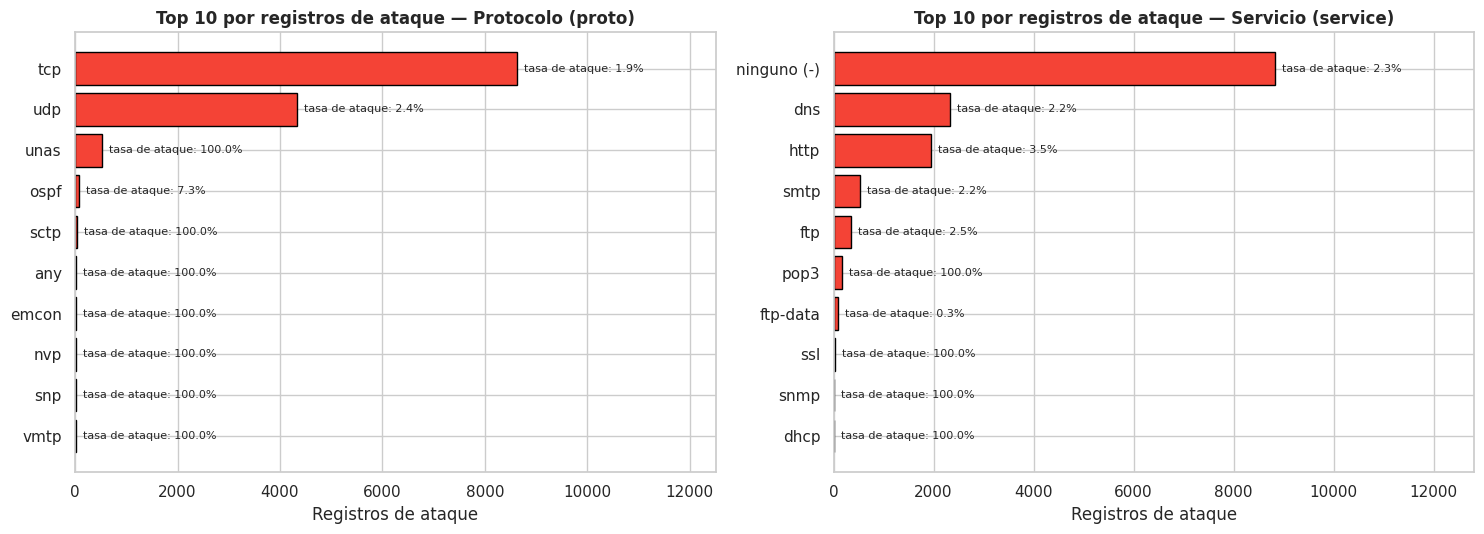

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 5.5))

for eje, tabla, titulo in zip(ejes, [tabla_proto, tabla_servicio],
                              ['Protocolo (proto)', 'Servicio (service)']):
    top = tabla.head(10).iloc[::-1]
    barras = eje.barh(top.index.astype(str), top['ataques'], color='#F44336', edgecolor='black')
    for barra, tasa in zip(barras, top['tasa_ataque']):
        eje.text(barra.get_width(), barra.get_y() + barra.get_height() / 2,
                 f'  tasa de ataque: {tasa:.1f}%', va='center', fontsize=8)
    eje.set_title(f'Top 10 por registros de ataque — {titulo}', fontsize=12, fontweight='bold')
    eje.set_xlabel('Registros de ataque')
    eje.set_xlim(0, top['ataques'].max() * 1.45)

plt.tight_layout()
plt.show()

In [ ]:
proto_principal = tabla_proto.index[0]
servicio_principal = tabla_servicio.index[0]

for nombre, tabla in [('protocolo', tabla_proto), ('servicio', tabla_servicio)]:
    primeros = tabla.head(3)
    detalle = ', '.join(f'{idx} ({fila.ataques:,.0f} ataques; {fila.participacion_en_ataques:.1f}% del total de ataques)'
                        for idx, fila in primeros.iterrows())
    print(f'Los tres {nombre}s con más registros de ataque son: {detalle}.')

    soporte = tabla[tabla['total'] >= 100]
    mayor_tasa = soporte['tasa_ataque'].idxmax()
    print(f'Entre los {nombre}s con al menos 100 registros, el de mayor tasa de ataque es {mayor_tasa} '
          f'({soporte.loc[mayor_tasa, "tasa_ataque"]:.1f}% de sus registros son ataques).\n')

Los tres protocolos con más registros de ataque son: tcp (8,622 ataques; 60.4% del total de ataques), udp (4,326 ataques; 30.3% del total de ataques), unas (535 ataques; 3.7% del total de ataques).
Entre los protocolos con al menos 100 registros, el de mayor tasa de ataque es unas (100.0% de sus registros son ataques).

Los tres servicios con más registros de ataque son: ninguno (-) (8,834 ataques; 61.9% del total de ataques), dns (2,332 ataques; 16.3% del total de ataques), http (1,939 ataques; 13.6% del total de ataques).
Entre los servicios con al menos 100 registros, el de mayor tasa de ataque es pop3 (100.0% de sus registros son ataques).



#### C.3 PI2: Duración y bytes transmitidos en tráfico normal vs. ataques

Las variables de duración y volumen de bytes tienden a presentar distribuciones asimétricas con colas largas (se reporta el coeficiente de asimetría en la tabla), por lo que se emplea la prueba no paramétrica **U de Mann-Whitney**, que no supone normalidad. Debido a que con muestras muy grandes cualquier diferencia mínima resulta estadísticamente significativa, se complementa con el **tamaño del efecto** mediante la correlación biserial por rangos (*r*), cuyo signo positivo indica que los ataques tienden a presentar valores mayores que el tráfico normal. Se emplean los umbrales convencionales: |r| < 0.1 insignificante, < 0.3 pequeño, < 0.5 mediano y ≥ 0.5 grande.

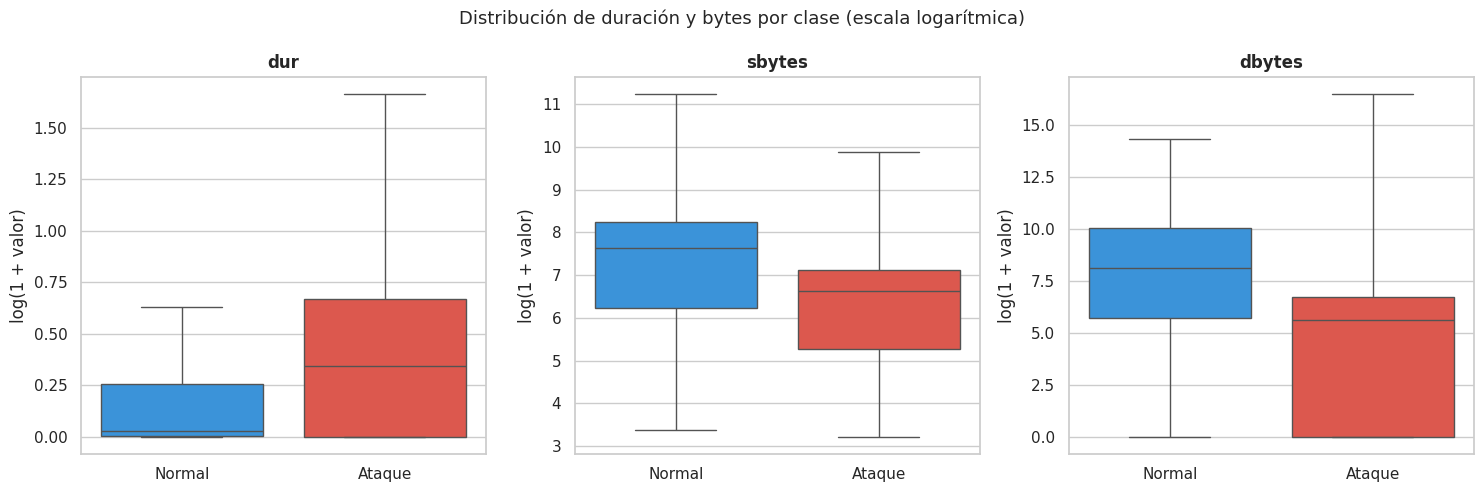

In [ ]:
variables_pi2 = ['dur', 'sbytes', 'dbytes']

fig, ejes = plt.subplots(1, 3, figsize=(15, 5))
for eje, variable in zip(ejes, variables_pi2):
    datos = pd.DataFrame({
        'clase': df['label'].map({0: 'Normal', 1: 'Ataque'}),
        'valor': np.log1p(df[variable])
    })
    sns.boxplot(data=datos, x='clase', y='valor', order=['Normal', 'Ataque'],
                palette={'Normal': '#2196F3', 'Ataque': '#F44336'}, showfliers=False, ax=eje)
    eje.set_title(variable, fontsize=12, fontweight='bold')
    eje.set_xlabel('')
    eje.set_ylabel('log(1 + valor)')

plt.suptitle('Distribución de duración y bytes por clase (escala logarítmica)', fontsize=13)
plt.tight_layout()
plt.show()

In [ ]:
def texto_p(p):
    return '< 1e-300' if p < 1e-300 else f'= {p:.3e}'


def magnitud_efecto(r):
    r = abs(r)
    if r < 0.1:
        return 'insignificante'
    if r < 0.3:
        return 'pequeño'
    if r < 0.5:
        return 'mediano'
    return 'grande'


filas = []
for variable in variables_pi2:
    ataque = df.loc[df['label'] == 1, variable]
    normal = df.loc[df['label'] == 0, variable]
    u, p = mannwhitneyu(ataque, normal, alternative='two-sided', method='asymptotic')
    r = 2 * u / (len(ataque) * len(normal)) - 1
    filas.append({
        'variable': variable,
        'asimetría': df[variable].skew(),
        'mediana normal': normal.median(),
        'mediana ataque': ataque.median(),
        'media normal': normal.mean(),
        'media ataque': ataque.mean(),
        'U': u,
        'valor_p': p,
        'efecto_r': r,
        'magnitud': magnitud_efecto(r)
    })

tabla_pi2 = pd.DataFrame(filas).set_index('variable')
tabla_pi2.style.format({
    'asimetría': '{:.2f}', 'mediana normal': '{:,.2f}', 'mediana ataque': '{:,.2f}',
    'media normal': '{:,.2f}', 'media ataque': '{:,.2f}', 'U': '{:,.0f}',
    'valor_p': lambda p: texto_p(p).lstrip('= '), 'efecto_r': '{:+.3f}'
})

,asimetría,mediana normal,mediana ataque,media normal,media ataque,U,valor_p,efecto_r,magnitud
variable,,,,,,,,,
dur,446.81,0.03,0.41,0.64,1.24,"4,728,994,810",9.079e-32,+0.057,insignificante
sbytes,186.27,"2,062.00",752.00,"4,622.44","18,168.97","2,963,812,884",< 1e-300,-0.337,mediano
dbytes,7.12,"3,380.00",268.00,"44,655.50","14,398.67","2,008,584,946",< 1e-300,-0.551,grande


In [ ]:
for variable, fila in tabla_pi2.iterrows():
    sentido = 'mayores' if fila['efecto_r'] > 0 else 'menores'
    if fila['valor_p'] < 0.05:
        print(f"{variable}: diferencia estadísticamente significativa (p {texto_p(fila['valor_p'])}). "
              f"Los ataques presentan valores {sentido} que el tráfico normal "
              f"(mediana {fila['mediana ataque']:,.2f} vs. {fila['mediana normal']:,.2f}); "
              f"magnitud del efecto {fila['magnitud']} (r = {fila['efecto_r']:+.3f}).")
    else:
        print(f"{variable}: no se encontró una diferencia estadísticamente significativa "
              f"(p {texto_p(fila['valor_p'])}) al nivel α = 0.05.")

dur: diferencia estadísticamente significativa (p = 9.079e-32). Los ataques presentan valores mayores que el tráfico normal (mediana 0.41 vs. 0.03); magnitud del efecto insignificante (r = +0.057).
sbytes: diferencia estadísticamente significativa (p < 1e-300). Los ataques presentan valores menores que el tráfico normal (mediana 752.00 vs. 2,062.00); magnitud del efecto mediano (r = -0.337).
dbytes: diferencia estadísticamente significativa (p < 1e-300). Los ataques presentan valores menores que el tráfico normal (mediana 268.00 vs. 3,380.00); magnitud del efecto grande (r = -0.551).


### D. Codificación, correlación y selección de variables predictoras

#### D.1 Codificación de variables categóricas

Las variables `proto`, `state` y `service` son texto y se convierten a valores numéricos mediante `LabelEncoder`.

In [ ]:
codificador = LabelEncoder()
for col in ['proto', 'state', 'service']:
    df[col] = codificador.fit_transform(df[col].astype(str))
    print(f'{col}: codificada ✓')

print(f'\nDataset preparado: {df.shape[0]:,} filas × {df.shape[1]} columnas')

proto: codificada ✓
state: codificada ✓
service: codificada ✓

Dataset preparado: 640,788 filas × 44 columnas


#### D.2 Matriz de correlación

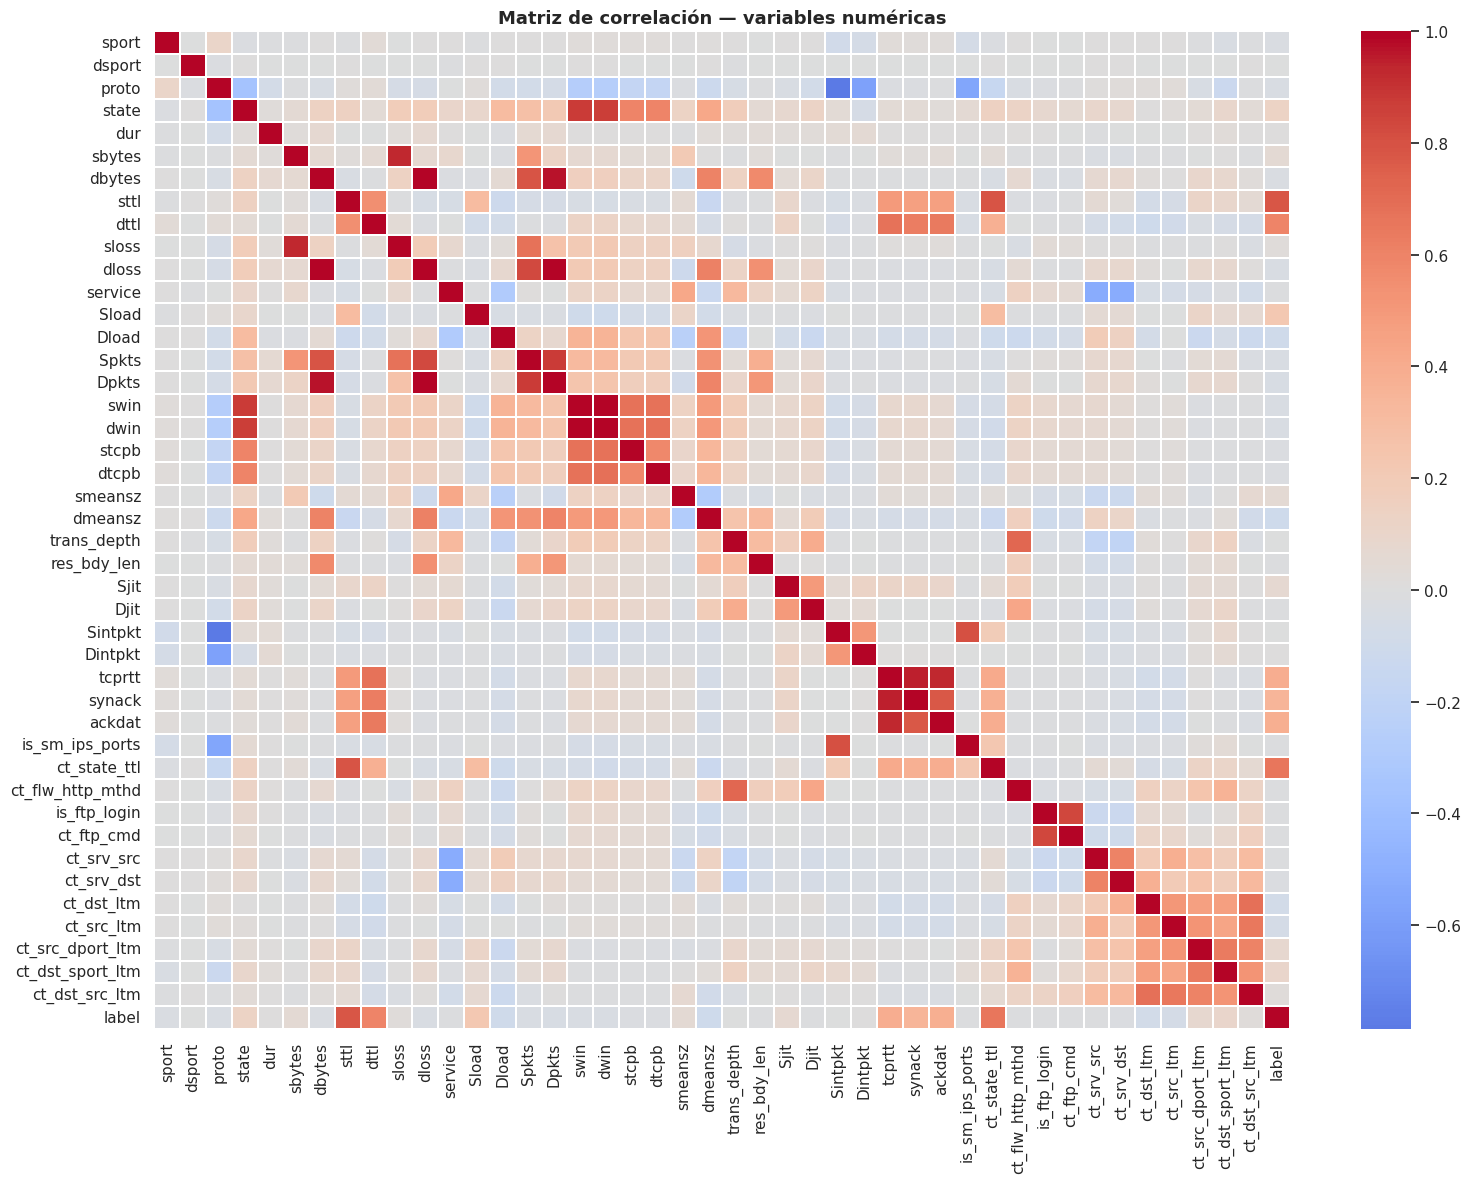

In [ ]:
cols_numericas = df.select_dtypes(include=[np.number]).columns
plt.figure(figsize=(16, 12))
sns.heatmap(df[cols_numericas].corr(), cmap='coolwarm', center=0, linewidths=0.3, annot=False)
plt.title('Matriz de correlación — variables numéricas', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

#### D.3 Selección de variables predictoras

Se separan las características (`X`) de la variable objetivo (`y`) y se filtran las variables poco útiles con dos criterios:

1. **Baja varianza:** las columnas casi constantes no aportan información al modelo.
2. **Alta correlación entre variables:** si dos variables están muy correlacionadas (redundantes), se elimina una de cada par para reducir la dimensionalidad y evitar la multicolinealidad.

In [ ]:
df.dropna(subset=['label'], inplace=True)

X = df.drop(columns=['label'])
y = df['label'].values

print(f'Matriz de características X (antes de filtrar): {X.shape}')

Matriz de características X (antes de filtrar): (640788, 43)


In [ ]:
umbral_varianza = 0.2

selector_var = VarianceThreshold(threshold=umbral_varianza)
selector_var.fit(X)

cols_baja_varianza = X.columns[~selector_var.get_support()].tolist()
print(f'Variables eliminadas por baja varianza (umbral = {umbral_varianza}): {len(cols_baja_varianza)}')
print(cols_baja_varianza)

X = X.drop(columns=cols_baja_varianza)
print(f'\nMatriz X después del filtro de varianza: {X.shape}')

Variables eliminadas por baja varianza (umbral = 0.2): 8
['trans_depth', 'tcprtt', 'synack', 'ackdat', 'is_sm_ips_ports', 'ct_state_ttl', 'is_ftp_login', 'ct_ftp_cmd']

Matriz X después del filtro de varianza: (640788, 35)


In [ ]:
umbral_correlacion = 0.8

matriz_corr = X.corr().abs()
triangulo_superior = matriz_corr.where(np.triu(np.ones(matriz_corr.shape), k=1).astype(bool))

cols_alta_correlacion = [col for col in triangulo_superior.columns
                         if any(triangulo_superior[col] > umbral_correlacion)]
print(f'Variables eliminadas por alta correlación (umbral = {umbral_correlacion}): {len(cols_alta_correlacion)}')
print(cols_alta_correlacion)

X = X.drop(columns=cols_alta_correlacion)
print(f'\nMatriz X final: {X.shape}')
print(f'\nVariables predictoras utilizadas: {list(X.columns)}')

Variables eliminadas por alta correlación (umbral = 0.8): 6
['sloss', 'dloss', 'Spkts', 'Dpkts', 'swin', 'dwin']

Matriz X final: (640788, 29)

Variables predictoras utilizadas: ['sport', 'dsport', 'proto', 'state', 'dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'service', 'Sload', 'Dload', 'stcpb', 'dtcpb', 'smeansz', 'dmeansz', 'res_bdy_len', 'Sjit', 'Djit', 'Sintpkt', 'Dintpkt', 'ct_flw_http_mthd', 'ct_srv_src', 'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm']


### E. Tipo de modelo, división de datos y normalización

El problema se aborda como **clasificación binaria supervisada**. Se comparan tres algoritmos con la misma partición de datos: un **Árbol de Decisión**, un **Random Forest** (100 árboles) y un **MLP** con arquitectura 150 → 100 → 50. La partición es 80 % para entrenamiento y 20 % para prueba, estratificada por clase. Los modelos basados en árboles no son sensibles a la escala de las variables, por lo que se entrenan con los datos originales; el MLP sí requiere normalización, por lo que se entrena con los datos estandarizados (el escalador se ajusta únicamente con el conjunto de entrenamiento).

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f'Entrenamiento: {x_train.shape[0]:,} registros (80%)')
print(f'Prueba:        {x_test.shape[0]:,} registros (20%)')

Entrenamiento: 512,630 registros (80%)
Prueba:        128,158 registros (20%)


In [ ]:
escalador = StandardScaler().fit(x_train)
trainX_scaled = escalador.transform(x_train)
testX_scaled = escalador.transform(x_test)

print('Normalización aplicada (media = 0, desviación = 1) ✓')

Normalización aplicada (media = 0, desviación = 1) ✓


### F. Entrenamiento de los modelos

In [ ]:
modelos = {
    'Árbol de Decisión': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'MLP': MLPClassifier(hidden_layer_sizes=(150, 100, 50), activation='relu',
                         solver='adam', max_iter=300, random_state=42)
}

datos_modelo = {
    'Árbol de Decisión': (x_train, x_test),
    'Random Forest': (x_train, x_test),
    'MLP': (trainX_scaled, testX_scaled)
}

tiempos_entrenamiento = {}
for nombre, modelo in modelos.items():
    print(f'Entrenando {nombre}...')
    inicio = time.perf_counter()
    modelo.fit(datos_modelo[nombre][0], y_train)
    tiempos_entrenamiento[nombre] = time.perf_counter() - inicio
    print(f'  Completado en {tiempos_entrenamiento[nombre]:.1f} s ✓')

arbol = modelos['Árbol de Decisión']
print(f'\nÁrbol de Decisión: profundidad = {arbol.get_depth()}, hojas = {arbol.get_n_leaves():,}')
print(f'Random Forest: {len(modelos["Random Forest"].estimators_)} árboles')
print(f'MLP: Entrada({X.shape[1]}) → 150 → 100 → 50 → Salida, {modelos["MLP"].n_iter_} iteraciones')

Entrenando Árbol de Decisión...
  Completado en 3.4 s ✓
Entrenando Random Forest...
  Completado en 93.2 s ✓
Entrenando MLP...
  Completado en 1279.5 s ✓

Árbol de Decisión: profundidad = 35, hojas = 1,012
Random Forest: 100 árboles
MLP: Entrada(29) → 150 → 100 → 50 → Salida, 43 iteraciones


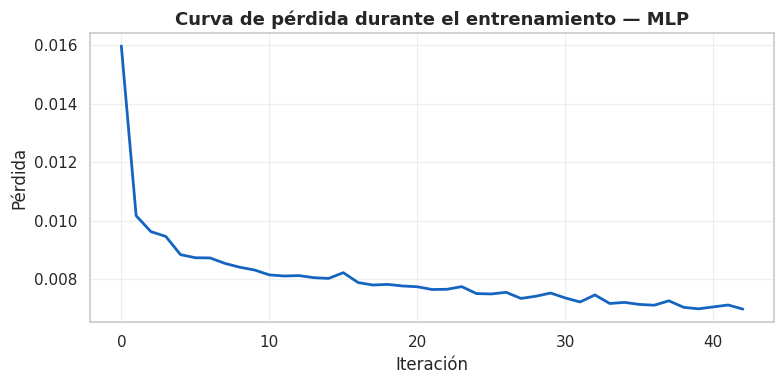

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(modelos['MLP'].loss_curve_, color='#1565C0', linewidth=2)
plt.title('Curva de pérdida durante el entrenamiento — MLP', fontsize=13, fontweight='bold')
plt.xlabel('Iteración')
plt.ylabel('Pérdida')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### G. Evaluación del rendimiento

Se evalúan los tres modelos sobre el conjunto de prueba con las siguientes métricas: *accuracy* (entrenamiento y prueba), *precisión*, *recall* y *F1* de la clase ataque, *F1* ponderado, error cuadrático medio (MSE), error absoluto medio (MAE), falsos negativos y falsos positivos, además de los tiempos de entrenamiento y de predicción. Para una clasificación binaria con predicciones de clase, el MSE y el MAE coinciden con la tasa de error.

In [ ]:
resultados = {}
predicciones = {}

for nombre, modelo in modelos.items():
    Xtr, Xte = datos_modelo[nombre]

    pred_train = modelo.predict(Xtr)
    inicio = time.perf_counter()
    pred_test = modelo.predict(Xte)
    tiempo_prediccion = time.perf_counter() - inicio

    tn, fp, fn, tp = confusion_matrix(y_test, pred_test, labels=[0, 1]).ravel()
    predicciones[nombre] = pred_test

    resultados[nombre] = {
        'Accuracy entrenamiento': accuracy_score(y_train, pred_train),
        'Accuracy prueba': accuracy_score(y_test, pred_test),
        'Precisión (ataque)': precision_score(y_test, pred_test),
        'Recall (ataque)': recall_score(y_test, pred_test),
        'F1 (ataque)': f1_score(y_test, pred_test),
        'F1 ponderado': f1_score(y_test, pred_test, average='weighted'),
        'MSE': mean_squared_error(y_test, pred_test),
        'MAE': mean_absolute_error(y_test, pred_test),
        'Falsos negativos': int(fn),
        'Falsos positivos': int(fp),
        'Tasa de falsos negativos (%)': fn / (fn + tp) * 100,
        'Tasa de falsos positivos (%)': fp / (fp + tn) * 100,
        'Tiempo de entrenamiento (s)': tiempos_entrenamiento[nombre],
        'Tiempo de predicción (s)': tiempo_prediccion
    }

resultados = pd.DataFrame(resultados).T
resultados.T.round(4)

,Árbol de Decisión,Random Forest,MLP
Accuracy entrenamiento,1.0000,1.0000,0.9966
Accuracy prueba,0.9972,0.9976,0.9963
Precisión (ataque),0.9376,0.9403,0.9353
Recall (ataque),0.9370,0.9545,0.8960
F1 (ataque),0.9373,0.9474,0.9152
F1 ponderado,0.9972,0.9976,0.9963
MSE,0.0028,0.0024,0.0037
MAE,0.0028,0.0024,0.0037
Falsos negativos,180.0000,130.0000,297.0000
Falsos positivos,178.0000,173.0000,177.0000


In [ ]:
for nombre in modelos:
    print('=' * 60)
    print(f'  {nombre}')
    print('=' * 60)
    print(classification_report(y_test, predicciones[nombre], target_names=['Normal (0)', 'Ataque (1)']))

  Árbol de Decisión
              precision    recall  f1-score   support

  Normal (0)       1.00      1.00      1.00    125302
  Ataque (1)       0.94      0.94      0.94      2856

    accuracy                           1.00    128158
   macro avg       0.97      0.97      0.97    128158
weighted avg       1.00      1.00      1.00    128158

  Random Forest
              precision    recall  f1-score   support

  Normal (0)       1.00      1.00      1.00    125302
  Ataque (1)       0.94      0.95      0.95      2856

    accuracy                           1.00    128158
   macro avg       0.97      0.98      0.97    128158
weighted avg       1.00      1.00      1.00    128158

  MLP
              precision    recall  f1-score   support

  Normal (0)       1.00      1.00      1.00    125302
  Ataque (1)       0.94      0.90      0.92      2856

    accuracy                           1.00    128158
   macro avg       0.97      0.95      0.96    128158
weighted avg       1.00      1.0

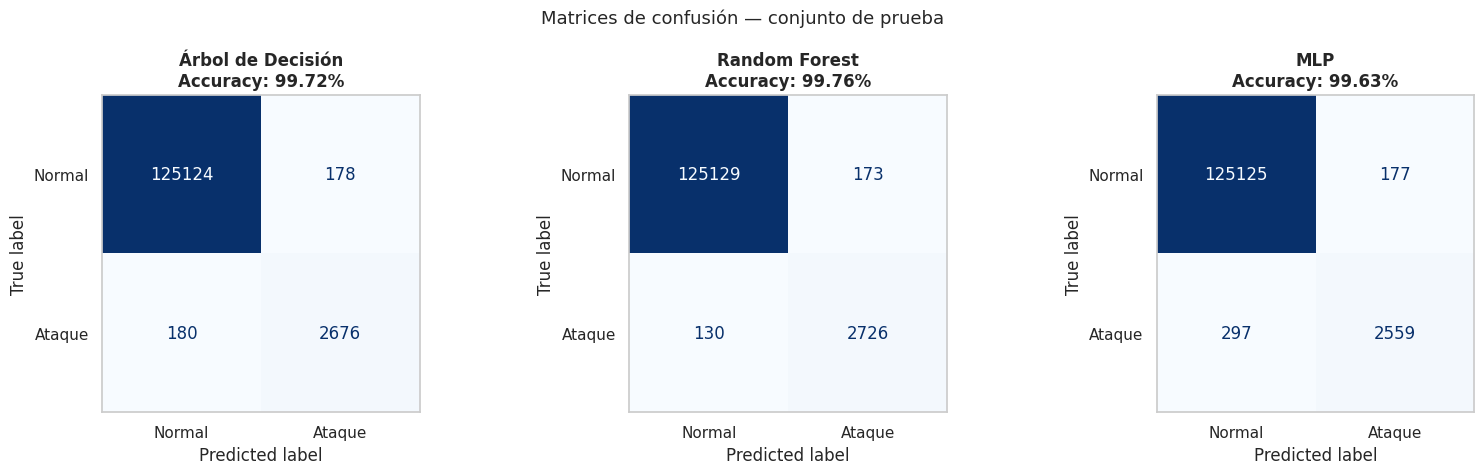

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.8))

for eje, nombre in zip(ejes, modelos):
    matriz = confusion_matrix(y_test, predicciones[nombre], labels=[0, 1])
    ConfusionMatrixDisplay(matriz, display_labels=['Normal', 'Ataque']).plot(
        ax=eje, colorbar=False, cmap='Blues', values_format='d')
    eje.set_title(f'{nombre}\nAccuracy: {resultados.loc[nombre, "Accuracy prueba"]*100:.2f}%',
                  fontsize=12, fontweight='bold')
    eje.grid(False)

plt.suptitle('Matrices de confusión — conjunto de prueba', fontsize=13)
plt.tight_layout()
plt.show()

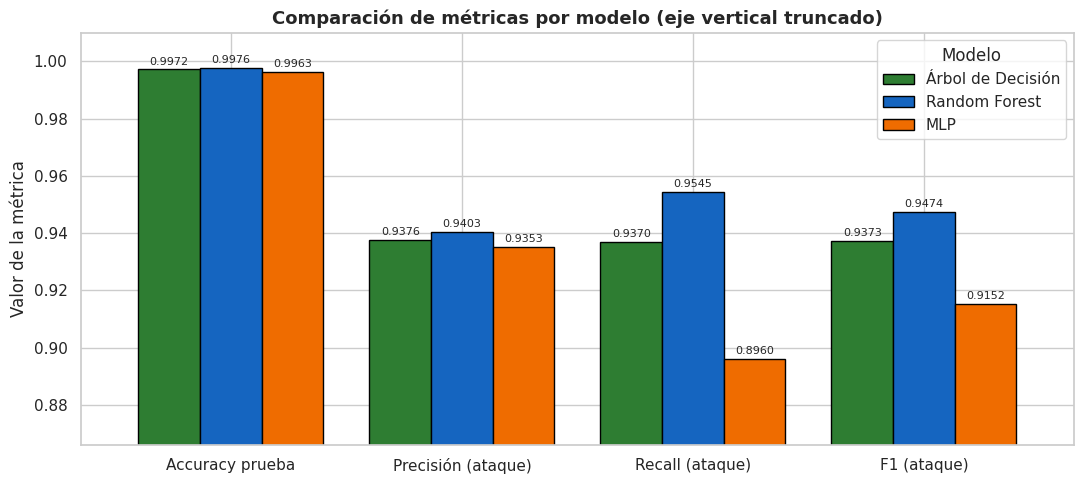

In [ ]:
metricas_barras = ['Accuracy prueba', 'Precisión (ataque)', 'Recall (ataque)', 'F1 (ataque)']
datos_barras = resultados[metricas_barras].astype(float).T

ax = datos_barras.plot(kind='bar', figsize=(11, 5), edgecolor='black', width=0.8,
                       color=['#2E7D32', '#1565C0', '#EF6C00'])
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt='%.4f', fontsize=8, padding=2)

ax.set_ylim(max(0, datos_barras.values.min() - 0.03), 1.01)
ax.set_title('Comparación de métricas por modelo (eje vertical truncado)', fontsize=13, fontweight='bold')
ax.set_ylabel('Valor de la métrica')
ax.set_xticklabels(metricas_barras, rotation=0)
ax.legend(title='Modelo')
plt.tight_layout()
plt.show()

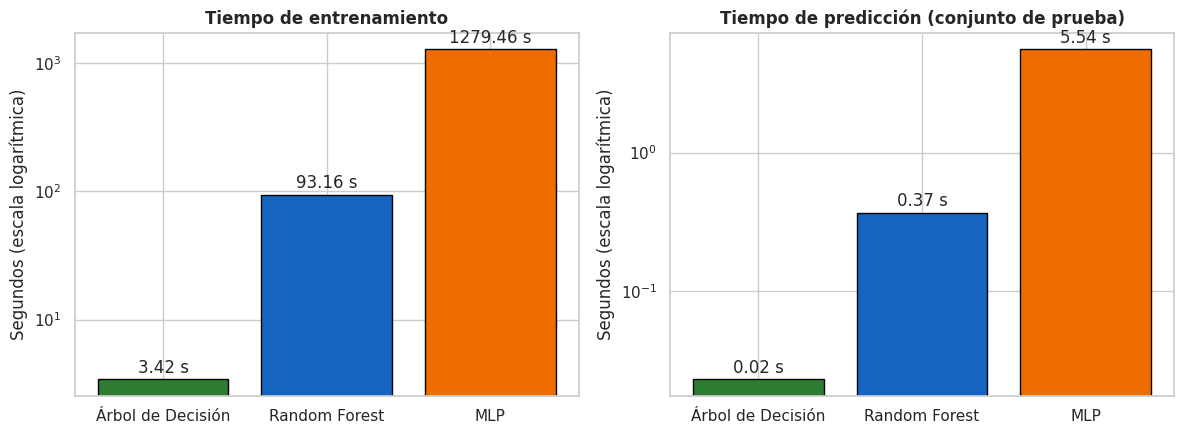

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))

for eje, columna, titulo in zip(ejes,
                                ['Tiempo de entrenamiento (s)', 'Tiempo de predicción (s)'],
                                ['Tiempo de entrenamiento', 'Tiempo de predicción (conjunto de prueba)']):
    barras = eje.bar(resultados.index, resultados[columna].astype(float),
                     color=['#2E7D32', '#1565C0', '#EF6C00'], edgecolor='black')
    eje.bar_label(barras, fmt='%.2f s', padding=2)
    eje.set_yscale('log')
    eje.set_title(titulo, fontsize=12, fontweight='bold')
    eje.set_ylabel('Segundos (escala logarítmica)')

plt.tight_layout()
plt.show()

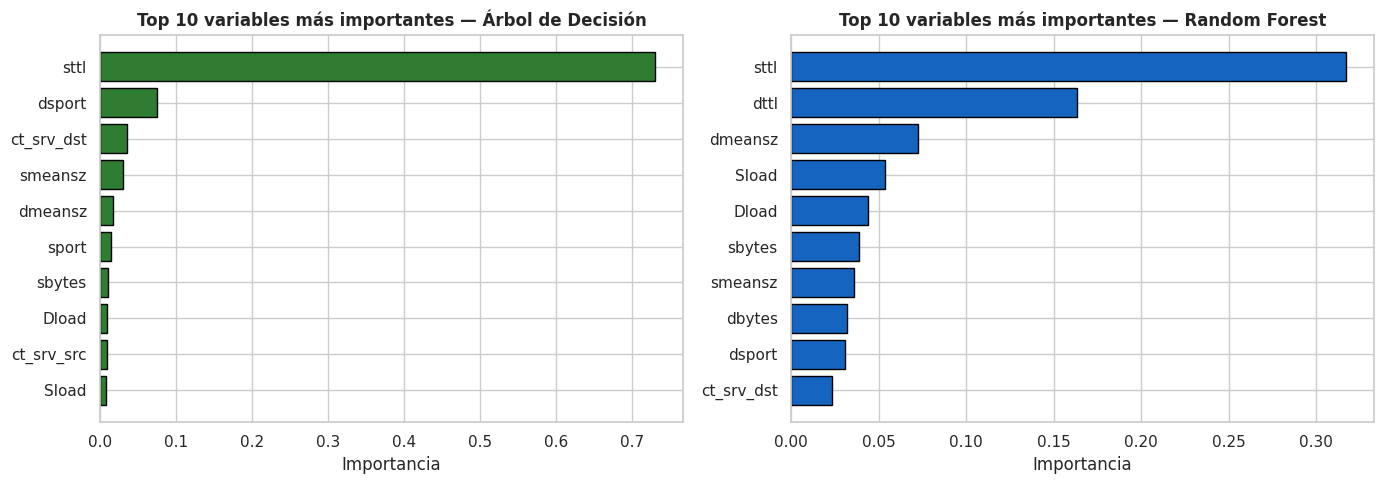

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))

for eje, nombre, color in zip(ejes, ['Árbol de Decisión', 'Random Forest'], ['#2E7D32', '#1565C0']):
    importancias = pd.Series(modelos[nombre].feature_importances_, index=x_train.columns)
    top = importancias.sort_values(ascending=False).head(10).iloc[::-1]
    eje.barh(top.index, top.values, color=color, edgecolor='black')
    eje.set_title(f'Top 10 variables más importantes — {nombre}', fontsize=12, fontweight='bold')
    eje.set_xlabel('Importancia')

plt.tight_layout()
plt.show()

### H. Análisis e interpretación de los resultados (PI3)

In [ ]:
mejor_f1 = resultados['F1 (ataque)'].astype(float).idxmax()
mejor_recall = resultados['Recall (ataque)'].astype(float).idxmax()
menos_fn = resultados['Falsos negativos'].astype(float).idxmin()
mas_rapido = resultados['Tiempo de predicción (s)'].astype(float).idxmin()

f1_ordenado = resultados['F1 (ataque)'].astype(float).sort_values(ascending=False)
diferencia_f1 = f1_ordenado.iloc[0] - f1_ordenado.iloc[1]

print('RENDIMIENTO EN LA CLASE ATAQUE (conjunto de prueba)\n')
for nombre, fila in resultados.iterrows():
    print(f'  {nombre}: precisión {fila["Precisión (ataque)"]:.4f} | recall {fila["Recall (ataque)"]:.4f} | '
          f'F1 {fila["F1 (ataque)"]:.4f} | ataques no detectados: {int(fila["Falsos negativos"]):,} '
          f'({fila["Tasa de falsos negativos (%)"]:.2f}%) | falsas alarmas: {int(fila["Falsos positivos"]):,}')

print(f'\nEl modelo con mayor F1 en la clase ataque es {mejor_f1} (F1 = {f1_ordenado.iloc[0]:.4f}), '
      f'con una ventaja de {diferencia_f1*100:.2f} puntos porcentuales sobre {f1_ordenado.index[1]}.')
if diferencia_f1 < 0.005:
    print('Esta diferencia es marginal (menor a 0.5 puntos porcentuales), por lo que el tiempo de predicción '
          'y el número de ataques no detectados pueden ser criterios de desempate.')
print(f'El modelo que detecta más ataques (mayor recall) es {mejor_recall}, y el que menos ataques deja pasar '
      f'en términos absolutos es {menos_fn}.')
print(f'El modelo con menor tiempo de predicción es {mas_rapido} '
      f'({resultados.loc[mas_rapido, "Tiempo de predicción (s)"]:.3f} s para {len(y_test):,} conexiones).')

print('\nBRECHA ENTRE ENTRENAMIENTO Y PRUEBA (indicador de sobreajuste)\n')
for nombre, fila in resultados.iterrows():
    brecha = (fila['Accuracy entrenamiento'] - fila['Accuracy prueba']) * 100
    print(f'  {nombre}: accuracy de entrenamiento {fila["Accuracy entrenamiento"]*100:.2f}% vs. '
          f'prueba {fila["Accuracy prueba"]*100:.2f}% (brecha de {brecha:.2f} puntos porcentuales)')

RENDIMIENTO EN LA CLASE ATAQUE (conjunto de prueba)

  Árbol de Decisión: precisión 0.9376 | recall 0.9370 | F1 0.9373 | ataques no detectados: 180 (6.30%) | falsas alarmas: 178
  Random Forest: precisión 0.9403 | recall 0.9545 | F1 0.9474 | ataques no detectados: 130 (4.55%) | falsas alarmas: 173
  MLP: precisión 0.9353 | recall 0.8960 | F1 0.9152 | ataques no detectados: 297 (10.40%) | falsas alarmas: 177

El modelo con mayor F1 en la clase ataque es Random Forest (F1 = 0.9474), con una ventaja de 1.00 puntos porcentuales sobre Árbol de Decisión.
El modelo que detecta más ataques (mayor recall) es Random Forest, y el que menos ataques deja pasar en términos absolutos es Random Forest.
El modelo con menor tiempo de predicción es Árbol de Decisión (0.023 s para 128,158 conexiones).

BRECHA ENTRE ENTRENAMIENTO Y PRUEBA (indicador de sobreajuste)

  Árbol de Decisión: accuracy de entrenamiento 100.00% vs. prueba 99.72% (brecha de 0.28 puntos porcentuales)
  Random Forest: accuracy de ent

## 4. Conclusiones

### 4.1 Hallazgos principales

In [ ]:
mejor_global = mejor_f1

print(f'1. Tras la limpieza se analizaron {len(df):,} conexiones de red, de las cuales '
      f'{conteo[1]/len(df)*100:.1f}% corresponde a ataques y {conteo[0]/len(df)*100:.1f}% a tráfico normal.')

print(f'\n2. PI1: el protocolo con más registros de ataque es {proto_principal} '
      f'({tabla_proto.iloc[0]["participacion_en_ataques"]:.1f}% de los ataques) y el servicio es {servicio_principal} '
      f'({tabla_servicio.iloc[0]["participacion_en_ataques"]:.1f}% de los ataques).')

print('\n3. PI2: resultados de la prueba U de Mann-Whitney entre tráfico normal y ataques:')
for variable, fila in tabla_pi2.iterrows():
    veredicto = 'diferencia significativa' if fila['valor_p'] < 0.05 else 'sin diferencia significativa'
    print(f'   - {variable}: {veredicto} (p {texto_p(fila["valor_p"])}), efecto {fila["magnitud"]} (r = {fila["efecto_r"]:+.3f}).')

print(f'\n4. PI3: el modelo con mejor F1 en la clase ataque fue {mejor_global} '
      f'(F1 = {resultados.loc[mejor_global, "F1 (ataque)"]:.4f}; recall = {resultados.loc[mejor_global, "Recall (ataque)"]:.4f}; '
      f'accuracy = {resultados.loc[mejor_global, "Accuracy prueba"]*100:.2f}%). '
      f'El de menor tiempo de predicción fue {mas_rapido}.')

1. Tras la limpieza se analizaron 640,788 conexiones de red, de las cuales 2.2% corresponde a ataques y 97.8% a tráfico normal.

2. PI1: el protocolo con más registros de ataque es tcp (60.4% de los ataques) y el servicio es ninguno (-) (61.9% de los ataques).

3. PI2: resultados de la prueba U de Mann-Whitney entre tráfico normal y ataques:
   - dur: diferencia significativa (p = 9.079e-32), efecto insignificante (r = +0.057).
   - sbytes: diferencia significativa (p < 1e-300), efecto mediano (r = -0.337).
   - dbytes: diferencia significativa (p < 1e-300), efecto grande (r = -0.551).

4. PI3: el modelo con mejor F1 en la clase ataque fue Random Forest (F1 = 0.9474; recall = 0.9545; accuracy = 99.76%). El de menor tiempo de predicción fue Árbol de Decisión.


### 4.2 Limitaciones

- Se utilizó únicamente el archivo `UNSW-NB15_1.csv`, que es una de las cuatro particiones del dataset completo; los resultados podrían variar con los datos restantes.
- La evaluación se basó en una única partición aleatoria estratificada 80/20, sin validación cruzada; por ello, las diferencias pequeñas entre modelos deben interpretarse con cautela.
- No se realizó optimización de hiperparámetros: los modelos se entrenaron con configuraciones por defecto (Árbol de Decisión y Random Forest) o fijas (MLP), por lo que su rendimiento podría mejorar con un ajuste específico.
- Las variables categóricas (`proto`, `state`, `service`) se codificaron con `LabelEncoder`, lo cual introduce un orden numérico arbitrario entre categorías nominales.
- Los tiempos de entrenamiento y predicción dependen del hardware y del entorno de ejecución, por lo que son comparables solo dentro de una misma ejecución.
- Al tratarse de tráfico sintético generado en laboratorio, el desempeño en redes reales podría diferir.
- Se abordó la clasificación binaria (normal/ataque); no se evaluó la identificación del tipo de ataque.

### 4.3 Trabajos futuros

- Validar los modelos con validación cruzada y con las cuatro particiones del dataset.
- Optimizar hiperparámetros (profundidad del árbol, número de estimadores, arquitectura y regularización del MLP).
- Probar codificaciones alternativas para variables nominales (por ejemplo, *one-hot encoding*) y técnicas de balanceo de clases.
- Extender el problema a clasificación multiclase para identificar la categoría de ataque.
- Evaluar los modelos con métricas orientadas al costo de los falsos negativos y en un escenario de detección en flujo continuo.

## Referencias

- Moustafa, N., & Slay, J. (2015). UNSW-NB15: a comprehensive data set for network intrusion detection systems (UNSW-NB15 network data set). *2015 Military Communications and Information Systems Conference (MilCIS)*, 1–6. IEEE.
- Moustafa, N., & Slay, J. (2016). The evaluation of network anomaly detection systems: Statistical analysis of the UNSW-NB15 data set and the comparison with the KDD99 data set. *Information Security Journal: A Global Perspective, 25*(1–3), 18–31.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.